# Sobol on Delta — Both vs Ambulance Only

What drives the additional benefit of adding facility pooling to ambulance pooling?


In [1]:
import sys
from pathlib import Path
_root = Path(".").resolve()
while not (_root / "paths.py").exists():
    _root = _root.parent
sys.path.insert(0, str(_root))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from SALib.analyze import sobol as sobol_analyze

RESULTS_PATH = _root / "data_cluster/sobol_no_t2_fixed_pooling/results.csv"
df = pd.read_csv(RESULTS_PATH)
print(f"Loaded {len(df)} runs")

UNCERTAINTIES = ["ccp_r1_same_bn_min", "ccp_r1_inter_bn_min", "bcas_rate", "waves_per_day", "wave_duration_min"]
OUTCOME = "death_rate_T1_BCAS"

both = df[(df["facility_eligibility"] == 1) & (df["ambulance_eligibility"] == 1)].sort_values("scenario").reset_index(drop=True)
amb = df[(df["facility_eligibility"] == 0) & (df["ambulance_eligibility"] == 1)].sort_values("scenario").reset_index(drop=True)
assert (both["scenario"].values == amb["scenario"].values).all()

delta = both[OUTCOME].values - amb[OUTCOME].values
print(f"Both vs Amb: {len(delta)} scenarios")
print(f"Delta range: {delta.min():.4f} to {delta.max():.4f}")
print(f"Median delta: {np.median(delta):.4f}")
print(f"Both better (delta < -0.01): {(delta < -0.01).sum()} ({(delta < -0.01).mean():.1%})")
print(f"Both worse (delta > 0.01): {(delta > 0.01).sum()} ({(delta > 0.01).mean():.1%})")

# EMA Sobol sampler orders parameters alphabetically
BOUNDS_MAP = dict(zip(UNCERTAINTIES, [[10, 20], [15, 35], [0.01, 0.07], [1, 6], [1, 60]]))
UNCERTAINTIES_SORTED = sorted(UNCERTAINTIES)
BOUNDS_SORTED = [BOUNDS_MAP[u] for u in UNCERTAINTIES_SORTED]

problem = {
    "num_vars": len(UNCERTAINTIES),
    "names": UNCERTAINTIES_SORTED,
    "bounds": BOUNDS_SORTED,
}

N = len(delta) // (2 * problem["num_vars"] + 2)
print(f"Inferred N = {N}")


Loaded 98304 runs
Both vs Amb: 24576 scenarios
Delta range: -0.6667 to 0.5000
Median delta: 0.0000
Both better (delta < -0.01): 6408 (26.1%)
Both worse (delta > 0.01): 1541 (6.3%)
Inferred N = 2048


## S1 and ST


                           ST   ST_conf
bcas_rate            0.790983  0.073513
ccp_r1_inter_bn_min  0.493284  0.062526
ccp_r1_same_bn_min   0.469878  0.056971
wave_duration_min    0.688722  0.071593
waves_per_day        0.806894  0.088431
                           S1   S1_conf
bcas_rate            0.093529  0.047816
ccp_r1_inter_bn_min  0.054033  0.035791
ccp_r1_same_bn_min  -0.003661  0.040696
wave_duration_min    0.035064  0.042047
waves_per_day        0.103089  0.056018
                                                 S2   S2_conf
(bcas_rate, ccp_r1_inter_bn_min)          -0.025256  0.069986
(bcas_rate, ccp_r1_same_bn_min)           -0.015346  0.069272
(bcas_rate, wave_duration_min)            -0.027986  0.078886
(bcas_rate, waves_per_day)                 0.018835  0.092473
(ccp_r1_inter_bn_min, ccp_r1_same_bn_min) -0.007049  0.063300
(ccp_r1_inter_bn_min, wave_duration_min)  -0.024575  0.068432
(ccp_r1_inter_bn_min, waves_per_day)      -0.044686  0.066059
(ccp_r1_same_bn_min, wav

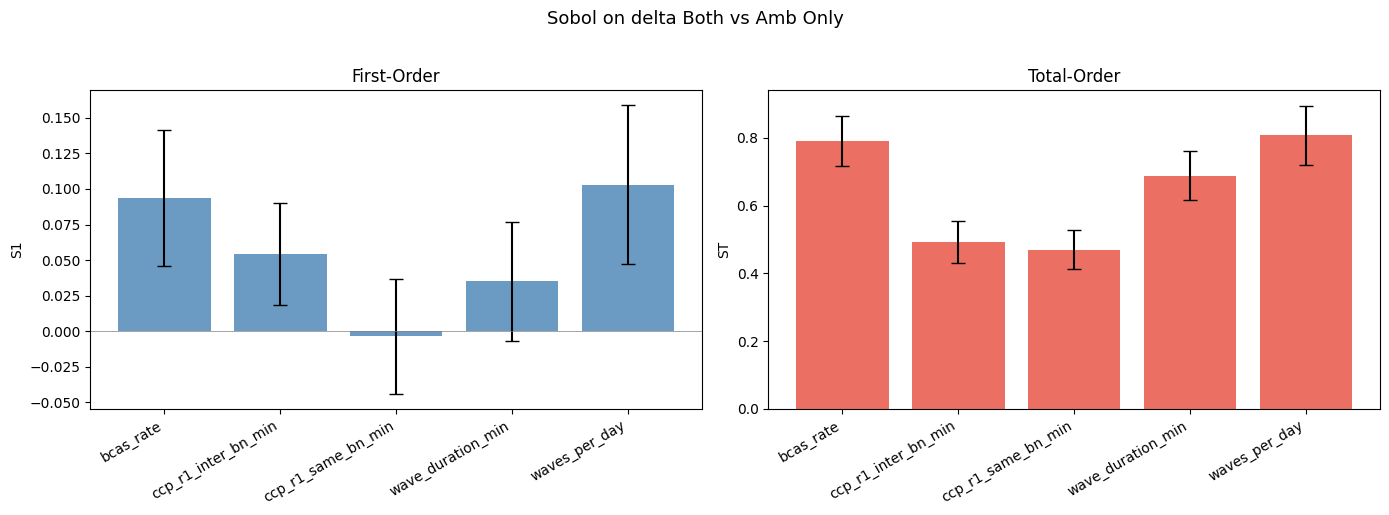

                         S1  S1_conf     ST  ST_conf
bcas_rate            0.0935   0.0478 0.7910   0.0735
ccp_r1_inter_bn_min  0.0540   0.0358 0.4933   0.0625
ccp_r1_same_bn_min  -0.0037   0.0407 0.4699   0.0570
wave_duration_min    0.0351   0.0420 0.6887   0.0716
waves_per_day        0.1031   0.0560 0.8069   0.0884


In [2]:
Si = sobol_analyze.analyze(problem, delta, calc_second_order=True, print_to_console=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
x_pos = np.arange(len(UNCERTAINTIES_SORTED))

axes[0].bar(x_pos, Si["S1"], yerr=Si["S1_conf"], capsize=5, color="steelblue", alpha=0.8)
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(UNCERTAINTIES_SORTED, rotation=30, ha="right")
axes[0].set_ylabel("S1")
axes[0].set_title("First-Order")
axes[0].axhline(0, color="grey", linewidth=0.5)

axes[1].bar(x_pos, Si["ST"], yerr=Si["ST_conf"], capsize=5, color="#e74c3c", alpha=0.8)
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(UNCERTAINTIES_SORTED, rotation=30, ha="right")
axes[1].set_ylabel("ST")
axes[1].set_title("Total-Order")
axes[1].axhline(0, color="grey", linewidth=0.5)

fig.suptitle("Sobol on delta Both vs Amb Only", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

print(pd.DataFrame({"S1": Si["S1"], "S1_conf": Si["S1_conf"], "ST": Si["ST"], "ST_conf": Si["ST_conf"]}, index=UNCERTAINTIES_SORTED).to_string(float_format="%.4f"))


## S2 — Pairwise Interactions


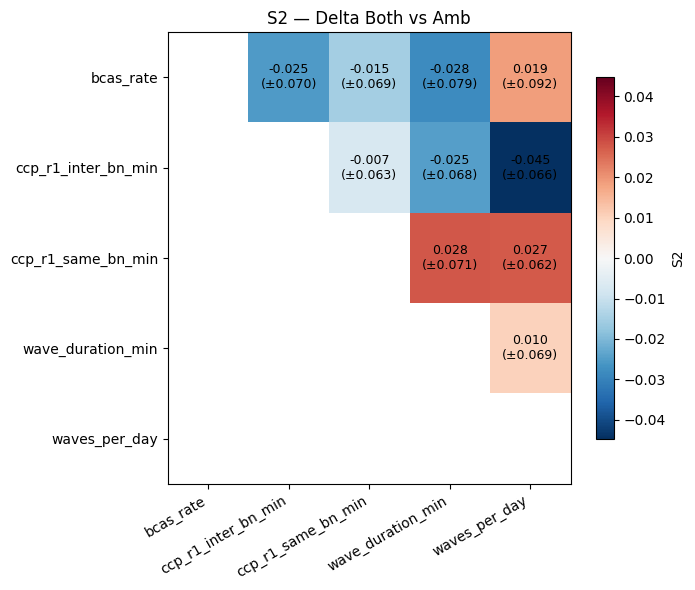

In [3]:
S2 = pd.DataFrame(Si["S2"], index=UNCERTAINTIES, columns=UNCERTAINTIES_SORTED)
S2_conf = pd.DataFrame(Si["S2_conf"], index=UNCERTAINTIES, columns=UNCERTAINTIES_SORTED)

fig, ax = plt.subplots(figsize=(7, 6))
mask = np.tril(np.ones_like(S2, dtype=bool), k=0)
s2_masked = S2.where(~mask)
vabs = max(0.01, np.nanmax(np.abs(s2_masked.values.astype(float))))
im = ax.imshow(s2_masked.values.astype(float), cmap="RdBu_r", vmin=-vabs, vmax=vabs, aspect="auto")
ax.set_xticks(range(len(UNCERTAINTIES_SORTED)))
ax.set_xticklabels(UNCERTAINTIES_SORTED, rotation=30, ha="right")
ax.set_yticks(range(len(UNCERTAINTIES_SORTED)))
ax.set_yticklabels(UNCERTAINTIES_SORTED)
ax.set_title("S2 — Delta Both vs Amb")
for i in range(len(UNCERTAINTIES_SORTED)):
    for j in range(len(UNCERTAINTIES_SORTED)):
        if not mask[i, j]:
            v = S2.iloc[i, j]
            c = S2_conf.iloc[i, j]
            if not np.isnan(v):
                ax.text(j, i, f"{v:.3f}\n(\u00b1{c:.3f})", ha="center", va="center", fontsize=9)
plt.colorbar(im, ax=ax, shrink=0.8, label="S2")
plt.tight_layout()
plt.show()
